# Qwen3: steering with a TPR probe

Does swapping the probe's role channels change Qwen's answer? We first look at the native swap, then compare it with raw centroids and centroids from TPR-reconstructed states.

The native swap exchanges the agent/patient filler profiles and maps their difference back to the hidden state with a pseudoinverse. The [walkthrough](native_tpr_role_swap.ipynb) works through that calculation.

The [comparison notebook](role_interventions_comparison_qwen3.ipynb) includes both TPR methods.


## Evaluation setup

The model is **Qwen3-8B-Base**. We edit both noun tokens together at one layer per forward pass, covering **layers 0–35**. Every method uses **α = 1**, with its own perturbation norm.

The prompt asks **Who or what is performing the action?** We compare the agent and patient answer-token logits at the final answer position. The plots show baseline preference, mean agent − patient logit, and strict prediction flips, separately for `test` / `gen_test` and active / passive sentences. Ties favor neither answer.


## Load the saved run

The plots use saved CSV/JSON results and run on CPU with NumPy, pandas, and matplotlib. Run from the repository root or `notebook/`. `AC_TPR_NATIVE_RUN` can point to another copy of the completed run. Figures stay inline; exports contain tables and provenance.


In [1]:
%matplotlib inline
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Run from the repository root or notebook directory"
RUN = Path(os.environ.get("AC_TPR_NATIVE_RUN", str(ROOT / "ac-tpr-cache/native-tpr-all-layers-20261109"))).expanduser().resolve()
FIGURES_ROOT = ROOT / "notebook/figures/role_interventions_tpr_qwen3"
METHODS = ['tpr_native_role_swap']
METHOD_LABELS = {
    "raw_centroid": "Centroid (by voice)",
    "tpr_native_role_swap": "TPR probe (native role swap)",
    "soft_native_slot_swap": "Soft TPR (native slot swap)",
}
SPLITS = ["test", "gen_test"]
VOICES = ["active", "passive"]
GROUPS = ["split", "voice"]
KEYS = GROUPS + ["layer", "method"]


### Check the run metadata

Verify the file hashes, model revision, layer list, and intervention settings.


In [3]:
source_paths = {name: RUN / name for name in (
    "plan.json", "evaluation/metadata.json", "evaluation/baseline.csv", "evaluation/results.csv",
)}
source_paths["corpus.csv"] = ROOT / "data/active_pass_long/corpus.csv"
source_hashes = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in source_paths.items()}
plan = json.loads(source_paths["plan.json"].read_text())
metadata = json.loads(source_paths["evaluation/metadata.json"].read_text())
assert metadata["status"] == "complete"
assert source_hashes["evaluation/results.csv"] == metadata["results_sha256"]
assert source_hashes["evaluation/baseline.csv"] == metadata["baseline_sha256"]
assert source_hashes["corpus.csv"] == plan["corpus_sha256"]
assert metadata["model"]["name"] == plan["model"] == "Qwen/Qwen3-8B-Base"
assert metadata["model"]["revision"] == plan["revision"]
assert metadata["layers"] == plan["layers"]
assert metadata["methods"] == plan["methods"]
assert metadata["alphas"] == [plan["fixed_alpha"]] == [1.0]
assert metadata["norm_matching"] is plan["norm_matching"] is False
assert set(METHODS) <= set(plan["methods"])
LAYERS = plan["layers"]


In [4]:
baseline_all = pd.read_csv(source_paths["evaluation/baseline.csv"])
results_all = pd.read_csv(source_paths["evaluation/results.csv"])
corpus = pd.read_csv(source_paths["corpus.csv"]).rename_axis("row_id")
assert len(baseline_all) == metadata["rows"] == sum(plan["expected_counts"][split] for split in SPLITS)
assert len(results_all) == metadata["result_rows"]
assert not baseline_all.row_id.duplicated().any()
assert not results_all.duplicated(["row_id", "layer", "method"]).any()
assert set(baseline_all.row_id) == set(corpus.index[corpus.split.isin(SPLITS)])
expected = pd.MultiIndex.from_product([baseline_all.row_id, LAYERS, plan["methods"]], names=["row_id", "layer", "method"])
assert results_all.set_index(["row_id", "layer", "method"]).index.sort_values().equals(expected.sort_values())
assert results_all.alpha.eq(1.0).all()
assert np.isfinite(baseline_all[["agent_logit", "patient_logit"]]).all().all()
assert np.isfinite(results_all[["baseline_margin", "edited_margin", "agent_edit_norm", "patient_edit_norm"]]).all().all()


### Attach sentence annotations

Match corpus rows to the recorded answers before applying filters.


In [5]:
# row_id is the position in the verified corpus; align annotations before filtering.
for column in ["split", "voice", "agent", "patient"]:
    np.testing.assert_array_equal(baseline_all[column], corpus.loc[baseline_all.row_id, column])
for column in ["split", "voice", "quad_id"]:
    np.testing.assert_array_equal(results_all[column], results_all.row_id.map(corpus[column]))
baseline_all["agent_minus_patient"] = baseline_all.agent_logit - baseline_all.patient_logit
np.testing.assert_array_equal(-results_all.baseline_margin, results_all.row_id.map(baseline_all.set_index("row_id").agent_minus_patient))
results_all = results_all[results_all.method.isin(METHODS)].copy()
FILTER_COLUMNS = [
    "subset", "verb_class", "np_type", "animacy_config", "animacy_hierarchy",
    "agent_animacy", "patient_animacy", "swapped",
]
baseline_all = baseline_all.merge(corpus[FILTER_COLUMNS], on="row_id", validate="one_to_one")
print(f"{plan['model']} / {len(baseline_all):,} sentences / layers {LAYERS} / α = 1")
print("Methods:", ", ".join(METHOD_LABELS[method] for method in METHODS))
display(pd.DataFrame([
    {"column": column, "value": value, "sentences": count}
    for column in FILTER_COLUMNS
    for value, count in baseline_all[column].value_counts().sort_index().items()
]))


Qwen/Qwen3-8B-Base / 2,096 sentences / layers [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35] / α = 1
Methods: TPR probe (native role swap)


,column,value,sentences
0,subset,mixed_contact,656
1,subset,names_agentive,628
2,subset,nouns_contact,812
3,verb_class,agentive,628
4,verb_class,contact,1468
5,np_type,mixed,656
6,np_type,name,628
7,np_type,noun,812
8,animacy_config,AA,1148
9,animacy_config,AI,374


## Choose the sentences

Set a filter to a list of values, or leave it as `None` to include everything. Filters on different columns combine with AND. The available values and counts are listed above.

`AA`, `AI`, `IA`, and `II` give agent then patient animacy. Rerun from the next cell after changing a filter. All plots and tables follow the selection, which gets its own export directory. Probes, centroids, and slot calibration stay fixed.


In [6]:
# None includes every value; a list selects one or more values.
FILTERS = {
    "subset": None,             # ["names_agentive"], ["nouns_contact"], ["mixed_contact"]
    "verb_class": None,         # ["agentive"], ["contact"]
    "np_type": None,            # ["name"], ["noun"], ["mixed"]
    "animacy_config": None,     # ["AA"], ["AI"], ["IA"], ["II"] (agent, patient)
    "animacy_hierarchy": None,  # ["equal"], ["aligned"], ["inverted"]
    "agent_animacy": None,      # ["animate"], ["inanimate"]
    "patient_animacy": None,    # ["animate"], ["inanimate"]
    "swapped": None,            # [0], [1]
}


In [7]:
baseline = baseline_all.copy()
active_filters = {}
for column, values in FILTERS.items():
    assert column in FILTER_COLUMNS, f"Unknown filter column: {column}"
    if values is None:
        continue
    assert isinstance(values, list) and values, f"Use a nonempty list or None for {column}"
    assert set(values) <= set(baseline_all[column].unique()), f"Unknown values for {column}: {values}"
    baseline = baseline.loc[baseline[column].isin(values)].copy()
    active_filters[column] = values
assert not baseline.empty, "No sentences match FILTERS; change the selection"
results = results_all.merge(baseline[["row_id"]], on="row_id", how="inner", validate="many_to_one")
assert len(results) == len(baseline) * len(LAYERS) * len(METHODS)
FILTER_LABEL = "; ".join(f"{column}={','.join(map(str, values))}" for column, values in active_filters.items()) or "All sentences"
selection = json.dumps(active_filters, sort_keys=True)
folder = "all" if not active_filters else "filtered-" + hashlib.sha256(selection.encode()).hexdigest()[:12]
FIGURES = FIGURES_ROOT / "all_layers" / folder


### Summarize the selected results

The saved margins are patient − agent. Reverse their sign for these plots, then count strict flips.


In [8]:
# Native result files store patient minus agent; reverse the sign for these plots.
results["baseline_agent_minus_patient"] = -results.baseline_margin
results["agent_minus_patient"] = -results.edited_margin
before, after = results.baseline_agent_minus_patient, results.agent_minus_patient
results["prediction_flipped"] = ((before > 0) & (after < 0)) | ((before < 0) & (after > 0))
summary = results.groupby(KEYS).agg(
    sentences=("agent_minus_patient", "size"),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
    flips=("prediction_flipped", "sum"),
    flip_rate=("prediction_flipped", "mean"),
    mean_agent_edit_norm=("agent_edit_norm", "mean"),
    mean_patient_edit_norm=("patient_edit_norm", "mean"),
).reset_index()
expected_keys = pd.MultiIndex.from_tuples([
    (*group, layer, method)
    for group in baseline.groupby(GROUPS).groups
    for layer in LAYERS for method in METHODS
], names=KEYS)
assert summary.set_index(KEYS).index.sort_values().equals(expected_keys.sort_values())
assert summary.flip_rate.between(0, 1).all()
print("Selection:", FILTER_LABEL)
print(f"Selected {len(baseline):,} / {len(baseline_all):,} sentences; {len(results):,} interventions")


Selection: All sentences
Selected 2,096 / 2,096 sentences; 75,456 interventions


## Before steering

What fraction of the selected sentences already favor the agent? Count `agent_logit > patient_logit` over all sentences in each panel; ties are not agent wins.


In [9]:
baseline_stats = baseline.groupby(GROUPS).agg(
    sentences=("agent_minus_patient", "size"),
    agent_wins=("agent_minus_patient", lambda values: (values > 0).sum()),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
).reindex(pd.MultiIndex.from_product([SPLITS, VOICES], names=GROUPS))
baseline_stats[["sentences", "agent_wins"]] = baseline_stats[["sentences", "agent_wins"]].fillna(0).astype(int)
baseline_stats["agent_preference"] = baseline_stats.agent_wins / baseline_stats.sentences
for group, rows in summary.groupby(GROUPS):
    assert (rows.sentences == baseline_stats.loc[group, "sentences"]).all()
display(baseline_stats[["sentences", "agent_wins", "agent_preference"]].round(4))
print(f"Overall agent preference: {baseline_stats.agent_wins.sum():,} / "
      f"{baseline_stats.sentences.sum():,} "
      f"({baseline_stats.agent_wins.sum() / baseline_stats.sentences.sum():.1%})")


sentences  agent_wins  agent_preference
split    voice                                           
test     active         208         208            1.0000
         passive        208         208            1.0000
gen_test active         840         840            1.0000
         passive        840         839            0.9988

Overall agent preference: 2,095 / 2,096 (100.0%)


In [10]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#334155",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 130,
})
COLORS = {"raw_centroid": "#64748b", "tpr_native_role_swap": "#0072B2", "soft_native_slot_swap": "#D55E00"}
FIGURES.mkdir(parents=True, exist_ok=True)

def show_figure(fig):
    """Display the figure inline and release its plotting resources."""
    plt.show()
    plt.close(fig)


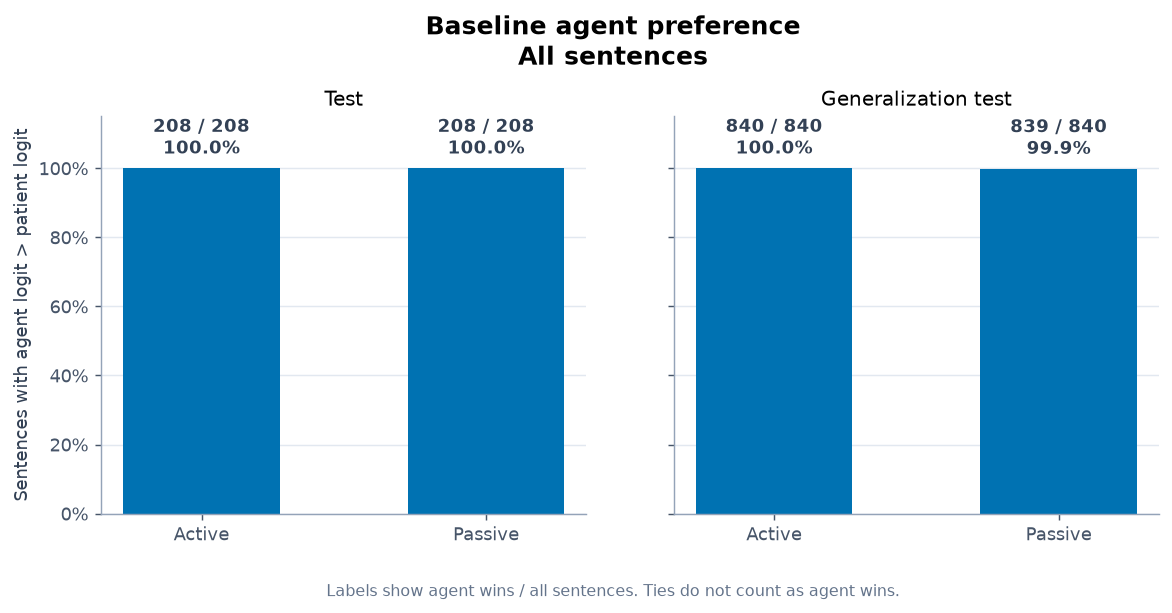

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.7), sharey=True)
for ax, split in zip(axes, SPLITS):
    stats = baseline_stats.loc[split].reindex(VOICES)
    ax.bar(np.arange(2), stats.agent_preference, width=0.55, color="#0072B2")
    for x, row in enumerate(stats.itertuples()):
        if row.sentences == 0:
            ax.text(x, 0.03, "No matching sentences", ha="center", va="bottom", fontsize=9)
            continue
        ax.text(x, row.agent_preference + 0.025,
                f"{row.agent_wins:,} / {row.sentences:,}\n{row.agent_preference:.1%}",
                ha="center", va="bottom", color="#334155", weight="bold")
    ax.set_title("Test" if split == "test" else "Generalization test")
    ax.set_xticks(range(2), [voice.capitalize() for voice in VOICES])
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e2e8f0")
axes[0].set_ylabel("Sentences with agent logit > patient logit")
fig.suptitle(f"Baseline agent preference\n{FILTER_LABEL}", fontsize=14, weight="bold", y=0.99)
fig.text(0.5, 0.035, "Labels show agent wins / all sentences. Ties do not count as agent wins.",
         ha="center", color="#64748b", fontsize=9)
fig.subplots_adjust(top=0.82, bottom=0.17, wspace=0.18)
show_figure(fig)


## Answer logits across layers

Positive agent − patient logits favor the agent. Each point is the mean over all selected sentences after an intervention at that layer. The dotted line is the unedited baseline.


The plotting helper keeps the axes and panel order consistent across the following figures.


In [12]:
def plot_layers(metric, title, ylabel, footnote, *, reference=False, percent=False, methods=None, statistics=None):
    """Compare intervention methods using common axes across split/voice panels."""
    methods = METHODS if methods is None else methods
    statistics = summary if statistics is None else statistics
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 8), sharex=True, sharey=True)
    for row_index, split in enumerate(SPLITS):
        for col_index, voice in enumerate(VOICES):
            ax = axes[row_index, col_index]
            data = statistics[(statistics.split == split) & (statistics.voice == voice)]
            stats = baseline_stats.loc[(split, voice)]
            if stats.sentences == 0:
                ax.text(0.5, 0.5, f"{split} / {voice}\nNo matching sentences", ha="center", va="center", transform=ax.transAxes)
                ax.set_axis_off()
                continue
            for method in methods:
                line = data[data.method == method].sort_values("layer")
                assert line.layer.tolist() == LAYERS
                ax.plot(line.layer, line[metric], color=COLORS[method], linewidth=1.9)
            ax.axhline(0, color="#64748b", linewidth=0.9, zorder=0)
            if reference:
                ax.axhline(stats.mean_agent_minus_patient, color="#334155", linestyle=":",
                           linewidth=1.5)
            split_title = "Test" if split == "test" else "Generalization test"
            denominator = f"n = {int(stats.sentences):,}"
            ax.set_title(f"{split_title} / {voice}  |  {denominator}", loc="left")
            ax.set_xlim(LAYERS[0], LAYERS[-1])
            ax.set_xticks(sorted(set(LAYERS[::4] + [LAYERS[-1]])))
            ax.grid(color="#e2e8f0", linewidth=0.65)
            ax.set_axisbelow(True)
            if percent:
                ax.set_ylim(0, min(1, max(0.05, np.ceil(statistics[metric].max() / 0.05) * 0.05)))
                ax.yaxis.set_major_formatter(PercentFormatter(1))
            if row_index == 1:
                ax.set_xlabel("Intervention layer (0-based)")
            if col_index == 0:
                ax.set_ylabel(ylabel)
    handles = [
        Line2D([0], [0], color=COLORS[method], linewidth=2, label=METHOD_LABELS[method])
        for method in methods
    ]
    if reference:
        handles.append(Line2D([0], [0], color="#334155", linestyle=":",
                              linewidth=1.5, label="Unedited baseline"))
    fig.suptitle(title, fontsize=16, weight="bold", y=0.985)
    fig.text(0.5, 0.945, f"Qwen3-8B-Base / joint noun edits / α = 1; norms not matched\n{FILTER_LABEL}",
             ha="center", va="top", color="#64748b", fontsize=9)
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.065),
               ncol=2, frameon=False, fontsize=10)
    fig.text(0.5, 0.017, footnote, ha="center", color="#64748b", fontsize=9)
    fig.subplots_adjust(top=0.87, bottom=0.27 if len(methods) > 3 else 0.23, hspace=0.28, wspace=0.12)
    show_figure(fig)


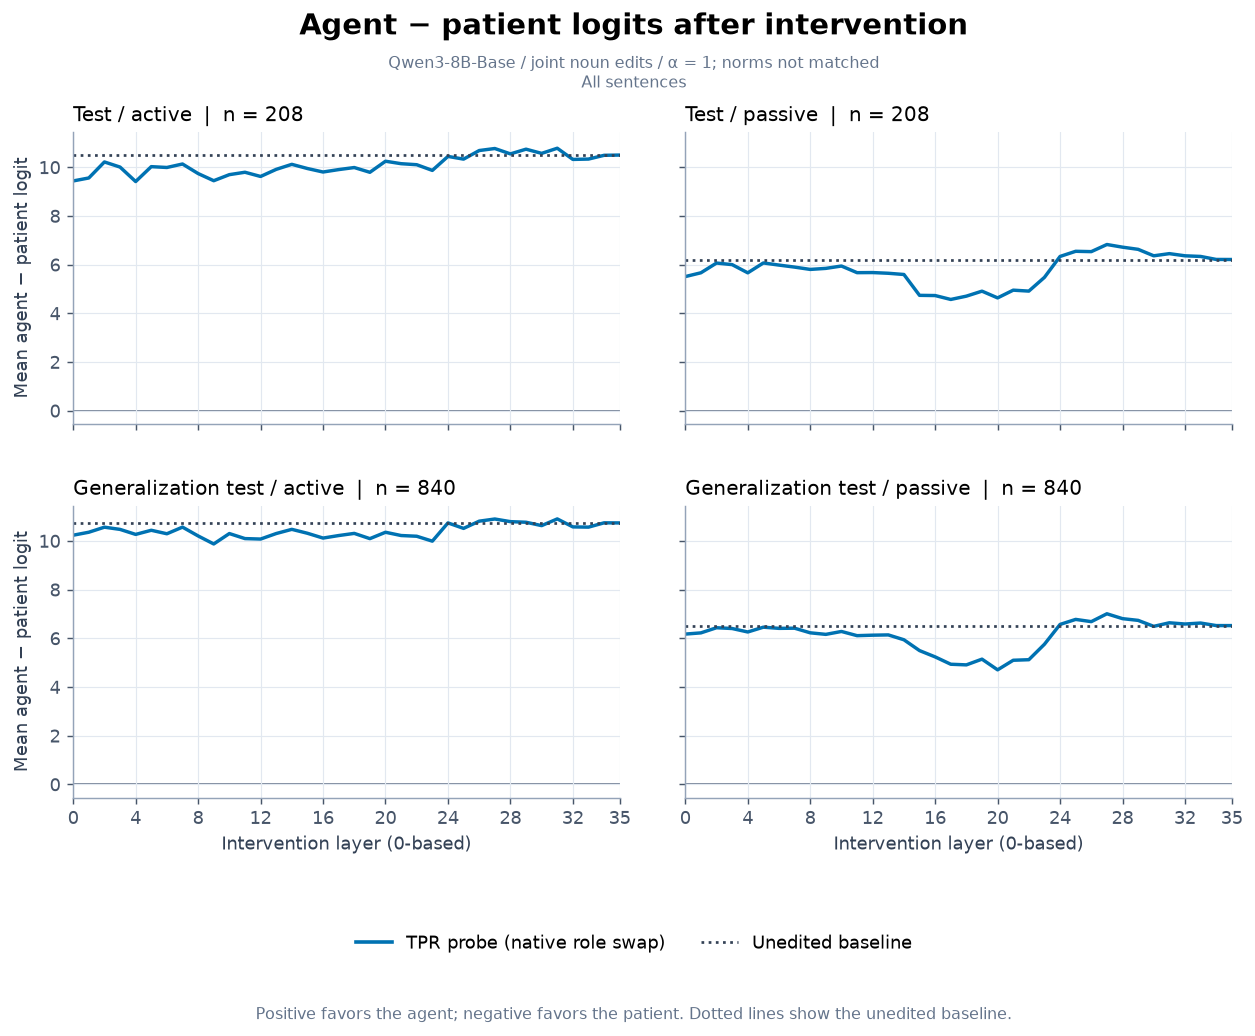

In [13]:
plot_layers(
    "mean_agent_minus_patient", "Agent − patient logits after intervention",
    "Mean agent − patient logit",
    "Positive favors the agent; negative favors the patient. Dotted lines show the unedited baseline.",
    reference=True,
)


## How often does the preference flip?

Count strict changes in either direction: agent → patient or patient → agent. Divide by **all selected sentences**. A tie before or after editing is not a flip.

Layer 35 is the no-effect control: after the final block, an edit at a noun position cannot affect the later answer position. All three original methods must reproduce the baseline there.


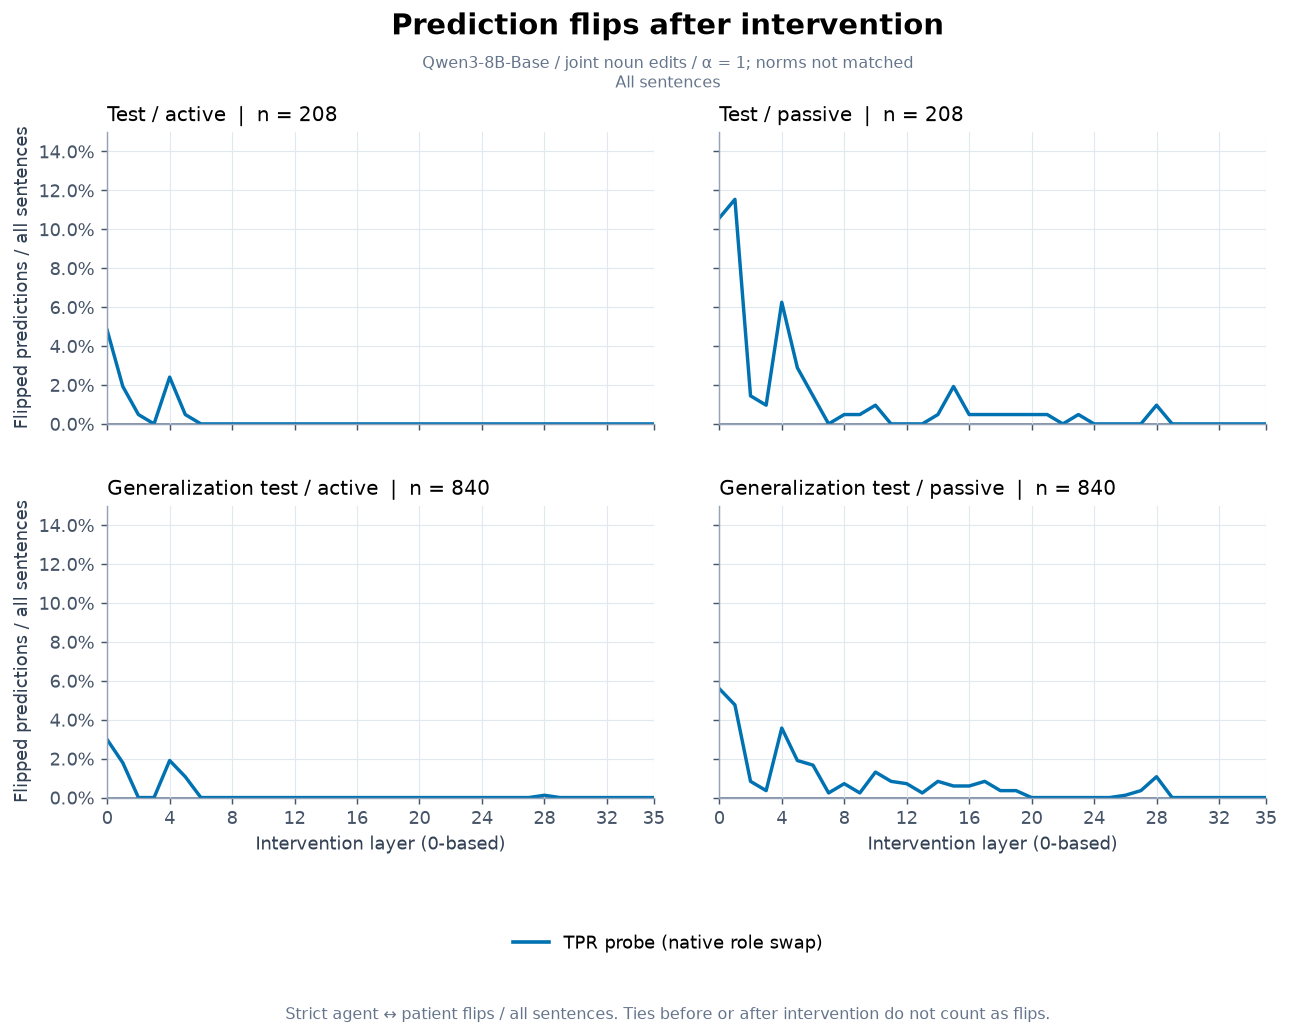

In [14]:
plot_layers(
    "flip_rate", "Prediction flips after intervention",
    "Flipped predictions / all sentences",
    "Strict agent ↔ patient flips / all sentences. Ties before or after intervention do not count as flips.",
    percent=True,
)


## Save the tables

Save baseline counts, layer statistics, and input hashes. The curves describe this corpus; no uncertainty intervals are estimated.


In [15]:
assert {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in source_paths.items()} == source_hashes
baseline_stats.to_csv(FIGURES / "baseline_statistics.csv")
summary.to_csv(FIGURES / "layer_statistics.csv", index=False)


In [16]:
provenance = {
    "filters": active_filters,
    "selected_sentences": len(baseline),
    "run_directory": str(RUN), "run_created_at": plan["created_at"],
    "model": metadata["model"], "methods": METHODS, "layers": LAYERS,
    "alpha": plan["fixed_alpha"], "norm_matching": plan["norm_matching"],
    "edited_positions": "Both noun tokens jointly at one layer per condition",
    "prompt_template": plan["prompt_template"], "demonstrations": plan["demonstrations"],
    "layer_selection": plan["layer_selection"],
    "source_paths": {name: str(path) for name, path in source_paths.items()},
    "source_sha256": source_hashes,
    "baseline_preference": "count(agent_logit > patient_logit) / all selected sentences",
    "answer_score": "mean(agent minus patient logit), computed as -edited_margin",
    "prediction_flip_rate": "strict agent-to-patient or patient-to-agent flips / all selected sentences",
    "ties": "Neither preference nor flip; included in the all-sentence denominator",
    "uncertainty": "Descriptive curves; no uncertainty intervals",
}
(FIGURES / "plot_metadata.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Tables and provenance saved to {FIGURES}")


Tables and provenance saved to /home/ldomenichelli/Workspace/AC-TPR-project/soft_tpr/native_interventions/notebook/figures/role_interventions_tpr_qwen3/all_layers/all


## Centroids from reconstructed states

We can also keep the centroid intervention and change the representation used to estimate it. TPR and Soft TPR each give a separate reconstruction and, from it, a separate training direction for every layer and voice.

### TPR reconstruction

Flatten the probe's binding map as $M$. The minimum-norm reconstruction is

$$\hat h_{\mathrm{TPR}}=c+s\left[\left(\frac{h-c}{s}M\right)M^+\right].$$

This projects the hidden state onto the learned binding subspace. It neither decodes predicted word labels nor swaps the role channels.


### Soft TPR reconstruction

Encode the normalized state, quantize its fillers, bind them in their original slots, and decode:

$$\hat h_{\mathrm{Soft}}=c+s\,D(\operatorname{bind}(q(h))).$$

Here the slots stay in their original order.


### From reconstructions to a steering direction

Average the reconstructed training noun states separately for agents and patients, within each voice and layer. For either reconstruction method,

$$d=\mu_{\mathrm{patient}}-\mu_{\mathrm{agent}},\qquad
h'_{\mathrm{agent}}=h_{\mathrm{agent}}+d,\qquad
h'_{\mathrm{patient}}=h_{\mathrm{patient}}-d.$$

Both noun positions are edited together at α = 1, without norm matching. The checkpoints stay fixed. Only training examples enter the means; the subgroup filters above select evaluation sentences and do not refit the direction.

### Optional: recompute the centroids

The completed results are loaded below. Leave both flags `False` to read them. Preparation uses CPU; evaluation needs the experiment's GPU environment.


In [17]:
# Cached results are used by default. Enable a stage to prepare or resume it.
# Preparation uses CPU; evaluation requires the experiment's GPU environment.
import subprocess
import sys
from datetime import datetime, timezone

CENTROID_RUN = RUN / "reconstructed_centroids"
PREPARE_CENTROIDS = False
RUN_CENTROID_EVALUATION = False
centroid_script = ROOT / "scripts/temporary/evaluate_reconstructed_centroids.py"


In [18]:
if PREPARE_CENTROIDS or RUN_CENTROID_EVALUATION:
    environment = os.environ.copy()
    environment.update(
        PYTHONPATH=os.pathsep.join([str(ROOT / "src"), str(ROOT / "scripts/temporary"),
                                  environment.get("PYTHONPATH", "")]),
        OMP_NUM_THREADS="2", MKL_NUM_THREADS="2", OPENBLAS_NUM_THREADS="2",
        HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1", TOKENIZERS_PARALLELISM="false",
    )
    if PREPARE_CENTROIDS:
        subprocess.run([sys.executable, str(centroid_script), "prepare", "--run-dir", str(RUN)],
                       cwd=ROOT, env=environment, check=True)
    if RUN_CENTROID_EVALUATION:
        # The report kernel disables CUDA; the evaluation subprocess uses GPU 0 by default.
        environment["CUDA_VISIBLE_DEVICES"] = os.environ.get("AC_TPR_CUDA_VISIBLE_DEVICES", "0")
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f")
        subprocess.run([
            sys.executable, "-u", str(ROOT / "scripts/temporary/resource_limited_run.py"),
            "--resource-log", str(CENTROID_RUN / f"resources-notebook-{stamp}.jsonl"),
            "--max-rss-gib", "48", "--min-available-gib", "32", "--gpu-fraction", "0.28",
            str(centroid_script), "evaluate", "--run-dir", str(RUN),
        ], cwd=ROOT, env=environment, check=True)


## Load the reconstructed-centroid results

Check that this evaluation uses the same baseline, model, and layer list.


In [19]:
CENTROID_METHODS = ['tpr_reconstructed_centroid']
CENTROID_ALL_METHODS = ["tpr_reconstructed_centroid", "soft_tpr_reconstructed_centroid"]
centroid_paths = {name: CENTROID_RUN / name for name in (
    "protocol.json", "centroids/metadata.json", "centroids/diagnostics.csv",
    "evaluation/metadata.json", "evaluation/results.csv",
)}
assert centroid_paths["evaluation/metadata.json"].is_file(), (
    "Reconstructed-centroid evaluation is not complete. Run the evaluation cell above or wait for the active run."
)
centroid_hashes = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in centroid_paths.items()}
centroid_protocol = json.loads(centroid_paths["protocol.json"].read_text())
centroid_fit = json.loads(centroid_paths["centroids/metadata.json"].read_text())
centroid_metadata = json.loads(centroid_paths["evaluation/metadata.json"].read_text())


In [20]:
assert centroid_metadata["status"] == centroid_fit["status"] == "complete"
assert centroid_protocol["layers"] == centroid_fit["layers"] == centroid_metadata["layers"] == LAYERS
assert centroid_protocol["methods"] == centroid_metadata["methods"] == CENTROID_ALL_METHODS
assert centroid_protocol["fit_split"] == centroid_fit["fit_split"] == "train"
assert centroid_protocol["plan_sha256"] == source_hashes["plan.json"]
assert centroid_metadata["protocol_sha256"] == centroid_fit["protocol_sha256"] == centroid_hashes["protocol.json"]
assert centroid_metadata["results_sha256"] == centroid_hashes["evaluation/results.csv"]
assert centroid_metadata["centroid_metadata_sha256"] == centroid_hashes["centroids/metadata.json"]
assert centroid_fit["diagnostics_sha256"] == centroid_hashes["centroids/diagnostics.csv"]
assert centroid_metadata["baseline_sha256"] == source_hashes["evaluation/baseline.csv"]
assert centroid_metadata["model"] == metadata["model"]
assert centroid_metadata["alpha"] == centroid_protocol["alpha"] == 1.0
assert centroid_metadata["norm_matching"] is centroid_protocol["norm_matching"] is False
for relative, expected_hash in centroid_protocol["extension_source_sha256"].items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected_hash, relative


### Check sentence coverage

There should be one result per sentence, layer, and centroid method.


In [21]:
centroid_results_all = pd.read_csv(centroid_paths["evaluation/results.csv"])
expected_centroid_keys = pd.MultiIndex.from_product(
    [baseline_all.row_id, LAYERS, CENTROID_ALL_METHODS], names=["row_id", "layer", "method"]
)
assert len(centroid_results_all) == centroid_metadata["result_rows"] == len(expected_centroid_keys)
assert centroid_metadata["rows"] == len(baseline_all)
assert not centroid_results_all.duplicated(["row_id", "layer", "method"]).any()
assert centroid_results_all.set_index(["row_id", "layer", "method"]).index.sort_values().equals(expected_centroid_keys.sort_values())
assert centroid_results_all.alpha.eq(1.0).all()
assert centroid_results_all.result_origin.eq("scored").all()
assert np.isfinite(centroid_results_all[["baseline_margin", "edited_margin", "agent_edit_norm", "patient_edit_norm"]]).all().all()
for column in ["split", "voice", "quad_id"]:
    np.testing.assert_array_equal(centroid_results_all[column], centroid_results_all.row_id.map(corpus[column]))
np.testing.assert_array_equal(-centroid_results_all.baseline_margin,
    centroid_results_all.row_id.map(baseline_all.set_index("row_id").agent_minus_patient))


### Final-layer control and training diagnostics

The final-layer answers must match the baseline exactly. The table also shows how the training reconstructions behave.


In [22]:
final_centroids = centroid_results_all[centroid_results_all.layer == LAYERS[-1]]
assert final_centroids.baseline_margin.eq(final_centroids.edited_margin).all(), "Final-block control failed"
centroid_diagnostics = pd.read_csv(centroid_paths["centroids/diagnostics.csv"])
assert len(centroid_diagnostics) == len(LAYERS) * len(CENTROID_ALL_METHODS) * len(VOICES)
display(centroid_diagnostics[centroid_diagnostics.method.isin(CENTROID_METHODS)].round(5))
print(f"Verified {len(centroid_results_all):,} scored centroid interventions over {len(LAYERS)} layers.")


,cosine_with_raw,direction_norm,layer,method,raw_direction_norm,reconstruction_mse,training_sentences,training_tokens_per_role,voice
0,0.21416,0.48473,0,tpr_reconstructed_centroid,2.26340,0.01596,1650,1650,active
1,0.14322,0.31311,0,tpr_reconstructed_centroid,2.18627,0.01566,1650,1650,passive
4,0.29761,1.02945,1,tpr_reconstructed_centroid,3.45903,0.02430,1650,1650,active
5,0.19040,0.66965,1,tpr_reconstructed_centroid,3.51700,0.02408,1650,1650,passive
8,0.18526,0.90387,2,tpr_reconstructed_centroid,4.87883,0.03152,1650,1650,active
...,...,...,...,...,...,...,...,...,...
133,0.24993,127.28463,33,tpr_reconstructed_centroid,509.28848,42.90436,1650,1650,passive
136,0.18625,139.22291,34,tpr_reconstructed_centroid,747.52232,73.03403,1650,1650,active
137,0.26125,163.23408,34,tpr_reconstructed_centroid,624.81380,58.30562,1650,1650,passive
140,0.13909,180.81348,35,tpr_reconstructed_centroid,1299.99751,164.86536,1650,1650,active


Verified 150,912 scored centroid interventions over 36 layers.


## Compare on the same sentences

Add each reconstructed centroid to the raw centroid and the corresponding native swap(s). Use the same sentence IDs selected above.


In [23]:
METHOD_LABELS.update({
    "tpr_reconstructed_centroid": "TPR reconstructed centroid",
    "soft_tpr_reconstructed_centroid": "Soft TPR reconstructed centroid",
})
COLORS.update({"tpr_reconstructed_centroid": "#009E73", "soft_tpr_reconstructed_centroid": "#CC79A7"})
CENTROID_COMPARE_METHODS = list(dict.fromkeys(["raw_centroid", *METHODS, *CENTROID_METHODS]))
# Use the identical selected sentence IDs, including when only one voice matches FILTERS.
original_results = pd.read_csv(source_paths["evaluation/results.csv"])
centroid_comparison_rows = pd.concat([
    original_results[original_results.method.isin(CENTROID_COMPARE_METHODS)],
    centroid_results_all[centroid_results_all.method.isin(CENTROID_METHODS)],
], ignore_index=True).merge(baseline[["row_id"]], on="row_id", how="inner", validate="many_to_one")
assert len(centroid_comparison_rows) == len(baseline) * len(LAYERS) * len(CENTROID_COMPARE_METHODS)
assert not centroid_comparison_rows.duplicated(["row_id", "layer", "method"]).any()
centroid_comparison_rows["agent_minus_patient"] = -centroid_comparison_rows.edited_margin
before, after = -centroid_comparison_rows.baseline_margin, centroid_comparison_rows.agent_minus_patient
centroid_comparison_rows["prediction_flipped"] = ((before > 0) & (after < 0)) | ((before < 0) & (after > 0))
centroid_summary = centroid_comparison_rows.groupby(KEYS).agg(
    sentences=("agent_minus_patient", "size"),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
    flips=("prediction_flipped", "sum"), flip_rate=("prediction_flipped", "mean"),
    mean_agent_edit_norm=("agent_edit_norm", "mean"), mean_patient_edit_norm=("patient_edit_norm", "mean"),
).reset_index()
for group, selected_group in baseline.groupby(GROUPS):
    rows = centroid_summary[(centroid_summary.split == group[0]) & (centroid_summary.voice == group[1])]
    assert len(rows) == len(LAYERS) * len(CENTROID_COMPARE_METHODS)
    assert rows.sentences.eq(len(selected_group)).all()
centroid_summary["mean_edit_norm"] = (centroid_summary.mean_agent_edit_norm + centroid_summary.mean_patient_edit_norm) / 2
centroid_comparison = centroid_summary.merge(
    baseline_stats[["agent_preference"]].reset_index(), on=GROUPS, validate="many_to_one"
)
centroid_comparison["Method"] = centroid_comparison.method.map(METHOD_LABELS)
display(centroid_comparison[["split", "voice", "layer", "Method", "sentences", "agent_preference",
    "mean_agent_minus_patient", "flips", "flip_rate", "mean_edit_norm"]].round(4))


,split,voice,layer,Method,sentences,agent_preference,mean_agent_minus_patient,flips,flip_rate,mean_edit_norm
0,gen_test,active,0,Centroid (by voice),840,1.0,10.7192,0,0.0000,2.2634
1,gen_test,active,0,TPR probe (native role swap),840,1.0,10.2330,25,0.0298,10.4329
2,gen_test,active,0,TPR reconstructed centroid,840,1.0,10.7353,0,0.0000,0.4847
3,gen_test,active,1,Centroid (by voice),840,1.0,10.6314,0,0.0000,3.4590
4,gen_test,active,1,TPR probe (native role swap),840,1.0,10.3552,15,0.0179,11.1804
...,...,...,...,...,...,...,...,...,...,...
427,test,passive,34,TPR probe (native role swap),208,1.0,6.2109,0,0.0000,225.9462
428,test,passive,34,TPR reconstructed centroid,208,1.0,6.2097,0,0.0000,163.2341
429,test,passive,35,Centroid (by voice),208,1.0,6.2085,0,0.0000,906.8789
430,test,passive,35,TPR probe (native role swap),208,1.0,6.2085,0,0.0000,318.3810


### Answer logits

The dotted line is the same unedited baseline. All methods use α = 1.


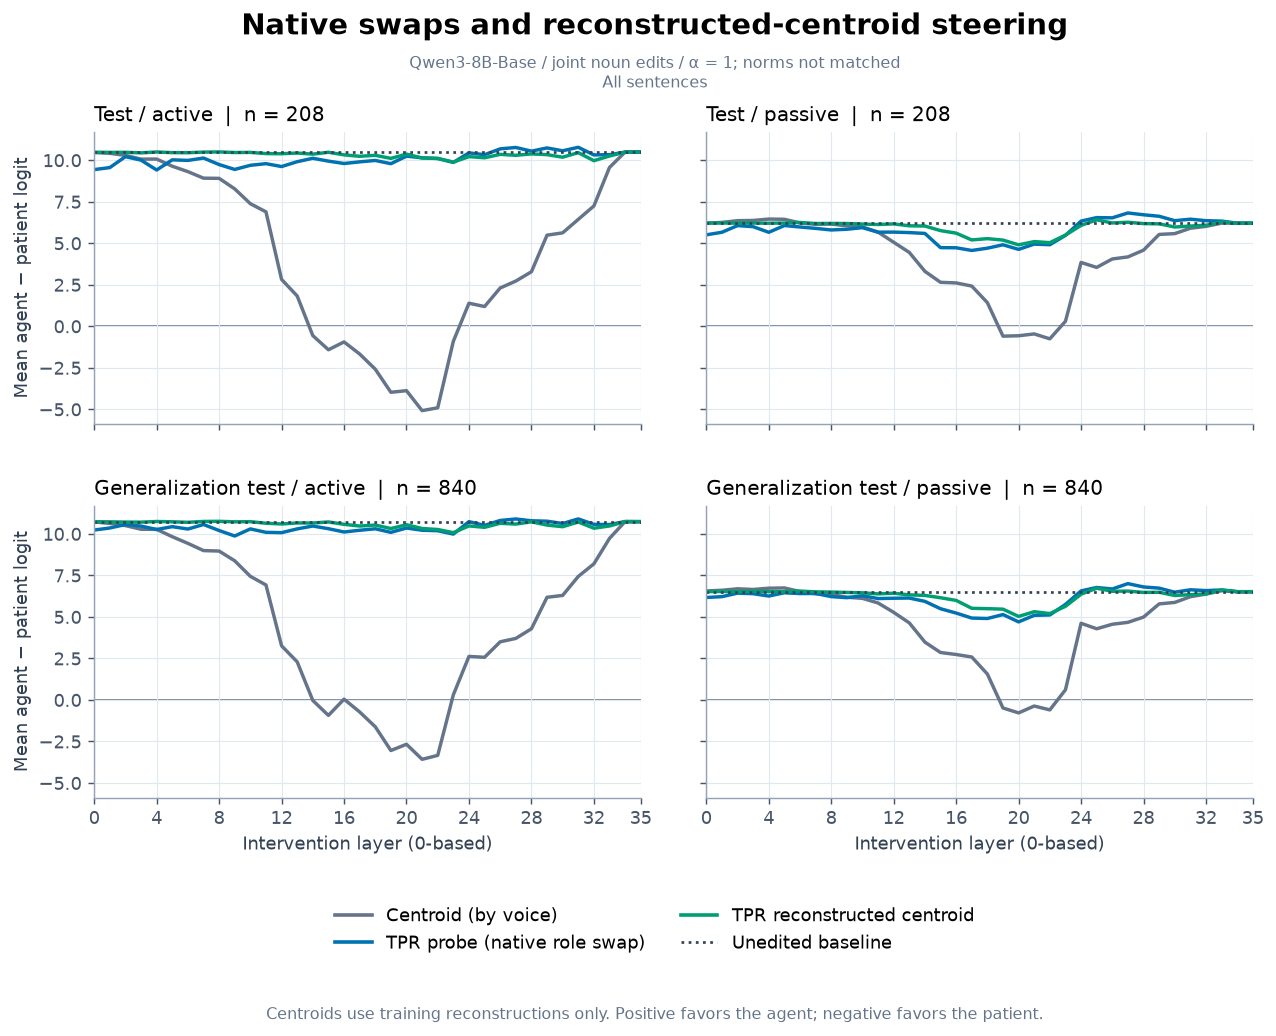

In [24]:
plot_layers(
    "mean_agent_minus_patient", "Native swaps and reconstructed-centroid steering",
    "Mean agent − patient logit",
    "Centroids use training reconstructions only. Positive favors the agent; negative favors the patient.",
    reference=True, methods=CENTROID_COMPARE_METHODS, statistics=centroid_summary,
)


### Prediction flips

Use the same strict, bidirectional definition and all-sentence denominator as above.


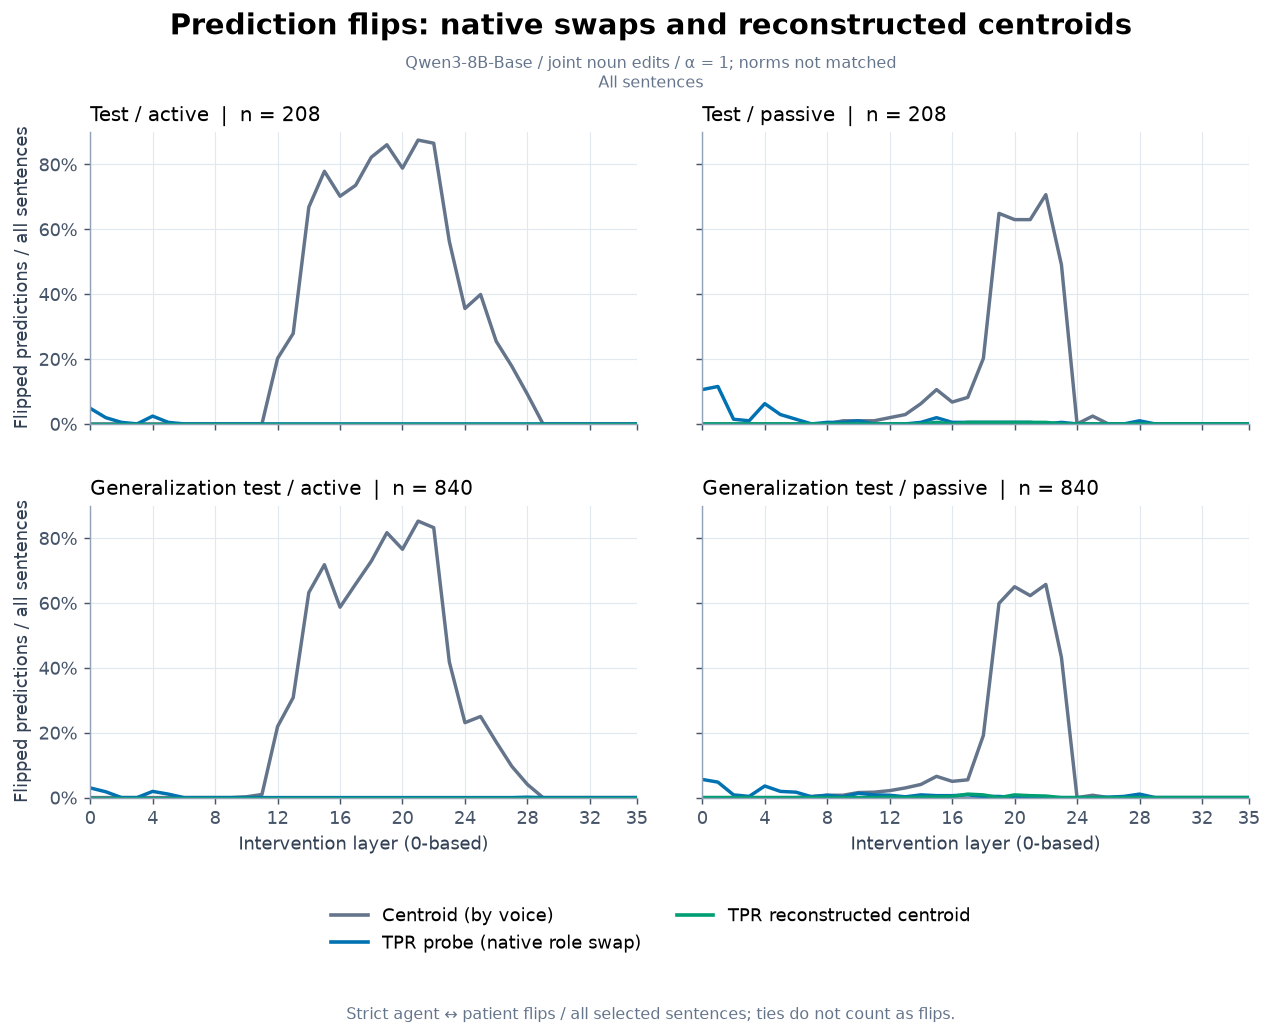

In [25]:
plot_layers(
    "flip_rate", "Prediction flips: native swaps and reconstructed centroids",
    "Flipped predictions / all sentences",
    "Strict agent ↔ patient flips / all selected sentences; ties do not count as flips.",
    percent=True, methods=CENTROID_COMPARE_METHODS, statistics=centroid_summary,
)


### Edit norms

This is the mean of the agent-token and patient-token perturbation norms. Read it alongside the logits and flips.


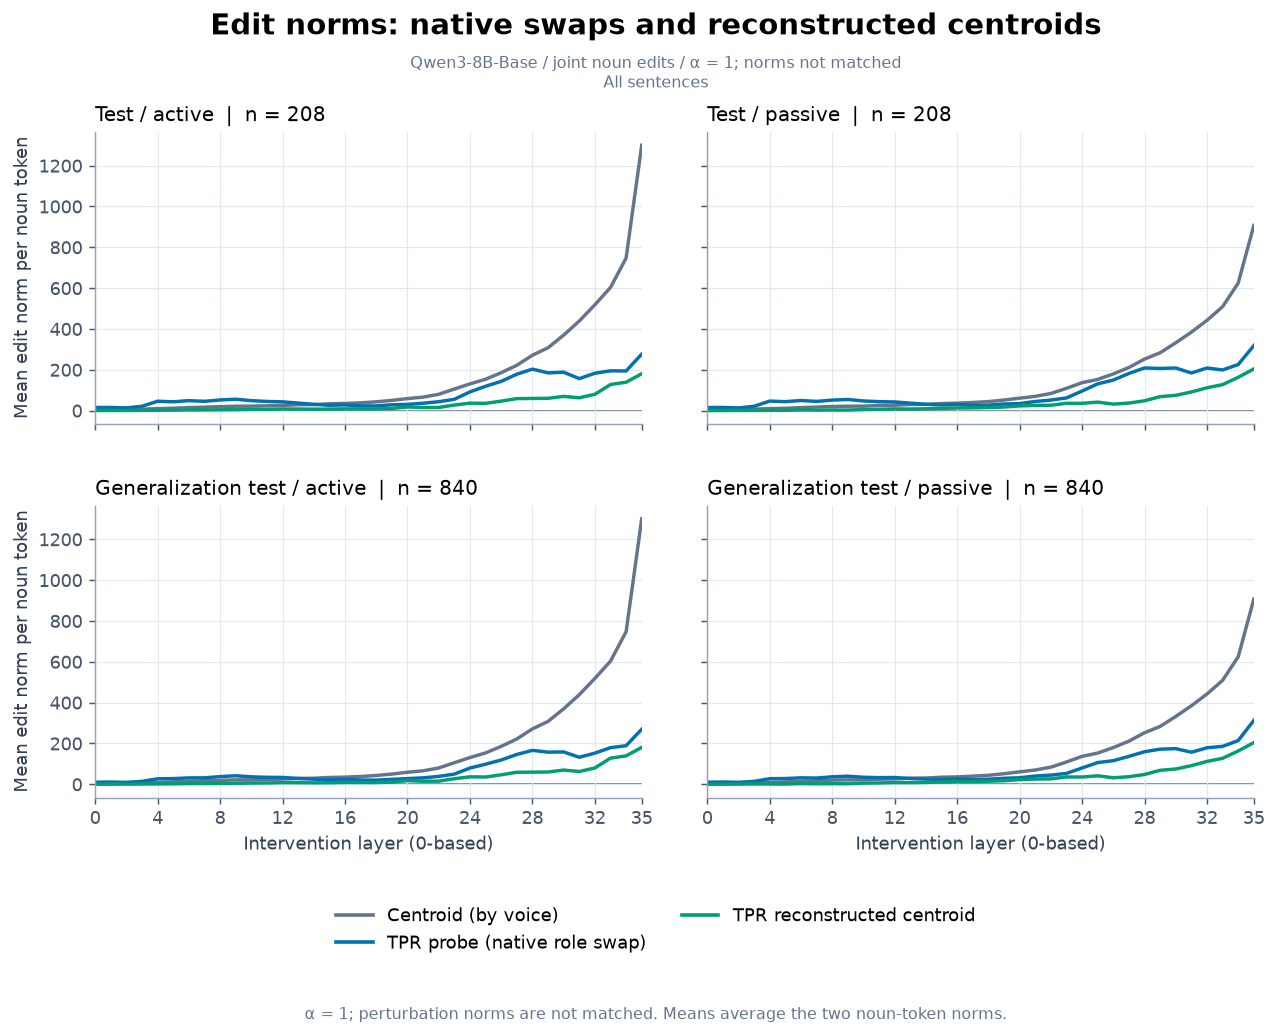

In [26]:
plot_layers(
    "mean_edit_norm", "Edit norms: native swaps and reconstructed centroids",
    "Mean edit norm per noun token",
    "α = 1; perturbation norms are not matched. Means average the two noun-token norms.",
    methods=CENTROID_COMPARE_METHODS, statistics=centroid_summary,
)


### Save the centroid comparison

Save the comparison tables, training diagnostics, and the hashes of the centroid inputs.


In [27]:
assert {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in centroid_paths.items()} == centroid_hashes
centroid_summary.to_csv(FIGURES / "reconstructed_centroid_layer_statistics.csv", index=False)
centroid_comparison.to_csv(FIGURES / "reconstructed_centroid_method_comparison.csv", index=False)
centroid_diagnostics[centroid_diagnostics.method.isin(CENTROID_METHODS)].to_csv(
    FIGURES / "reconstructed_centroid_training_diagnostics.csv", index=False
)
centroid_provenance = dict(provenance,
    methods=CENTROID_COMPARE_METHODS, reconstructed_centroid_methods=CENTROID_METHODS,
    centroid_fit_split="train", centroid_grouping=["voice", "role"],
    centroid_protocol=centroid_protocol,
    centroid_source_paths={name: str(path) for name, path in centroid_paths.items()},
    centroid_source_sha256=centroid_hashes,
)
(FIGURES / "reconstructed_centroid_plot_metadata.json").write_text(json.dumps(centroid_provenance, indent=2) + "\n")
print(f"Reconstructed-centroid tables and provenance saved to {FIGURES}")


Reconstructed-centroid tables and provenance saved to /home/ldomenichelli/Workspace/AC-TPR-project/soft_tpr/native_interventions/notebook/figures/role_interventions_tpr_qwen3/all_layers/all


## Reading the comparison

The native swap exchanges role-conditioned filler profiles for each token. The reconstructed centroid instead adds a fixed average direction within the binding subspace. Both use the same probe checkpoint, held-out sentences, baseline, prompts, and joint noun edits, but their perturbation norms differ.

All 36 layers are shown without choosing one from test outcomes. These are descriptive results for this corpus. A successful probe swap or slot recovery does not establish that Qwen preserves word identity; reconstruction alone does not guarantee that either.
